# Visualization with REFINED

Based on the code in:
https://github.com/omidbazgirTTU/REFINED

### 1. In the below cell we perform initialization with MDS

In [17]:
import pickle
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import scipy.misc
import Toolbox
from Toolbox import two_d_eq, Assign_features_to_pixels
from sklearn.manifold import MDS
from sklearn.metrics.pairwise import euclidean_distances
import math
import os
# os.chdir('C:\\Users\\obazgir\\Desktop\\CMDS_IMAGES_NEW\\')
#%% Loading the data
df = pd.read_csv("dataset.csv")

# Control NaN values
df = df.drop(columns = ['src_ip', 'Label'], axis = 1)
df.replace([np.inf, -np.inf], np.nan, inplace=True)  # Replace infinity with NaN
df.fillna(df.max(), inplace=True)

Feat_DF = df
#Feat_DF = pd.read_csv("C:\\Users\\obazgir\\Desktop\\CMDS_IMAGES_NEW\\normalized_padel_feats_NCI60_672.csv")

X = Feat_DF.values; # X = X[:,2:]
original_input = pd.DataFrame(data = X)                              # The MDS input should be in a dataframe format with rows as samples and columns as features
feature_names_list = original_input.columns.tolist()                 # Extracting feature_names_list (gene_names or descriptor_names)
print(">>>> Data  is loaded")

#%% MDS
nn = math.ceil(np.sqrt(len(feature_names_list))) 				     # Image dimension
Nn = original_input.shape[1] 										 # Number of features
    


>>>> Data  is loaded


In [18]:
if not os.path.exists('Mapping_REFINED.pickle'):
    transposed_input = original_input.T 							     # The MDS input data must be transposed , because we want summarize each feature by two values (as compard to regular dimensionality reduction each sample will be described by two values)
    Euc_Dist = euclidean_distances(transposed_input) 					 # Euclidean distance
    Euc_Dist = np.maximum(Euc_Dist, Euc_Dist.transpose())   			 # Making the Euclidean distance matrix symmetric

    embedding = MDS(n_components=2)										 # Reduce the dimensionality by MDS into 2 components
    mds_xy = embedding.fit_transform(transposed_input)					 # Apply MDS			

    print(">>>> MDS dimensionality reduction is done")

    eq_xy = two_d_eq(mds_xy,Nn)
    Img = Assign_features_to_pixels(eq_xy,nn,verbose=1)					# Img is the none-overlapping coordinates generated by MDS

    #%% To be saved for hill climbing
    Desc = Feat_DF.columns.tolist();  #  Desc = Desc[2:]					# Drug descriptors name
    Dist = pd.DataFrame(data = Euc_Dist, columns = Desc, index = Desc)	# Generating a distance matrix which includes the Euclidean distance between each and every descriptor
    data = (Desc, Dist, Img	)  											# Preparing the hill climbing inputs

    with open("Init_MDS_Euc.pickle", 'wb') as f:					# The hill climbing input is a pickle, therefore everything is saved as a pickle to be loaded by the hill climbing
        pickle.dump(data, f)

### 2. Hill Climbing
Once the initializaiton is performed, then we have to apply the search optimizaition (hill climbing). The below bash script will run the search optimization.

In [19]:
# !"C:\\Python312\\python" "process_md5.py" --init Init_MDS_Euc.pickle   --mapping Mapping_REFINED.pickle  --evolution REFINED_Evolve.csv --num 1

### 3. Visualization
Once the search optimization is performed and the coordinates for features are obtained, we can use the coordinates to generate images for visualization purpose or training CNNs. In the below code visualization is performed.

In [20]:
#%% Visualizing REFFINED images
import math
import pickle
from Toolbox import REFINED_Im_Gen
# MDS
with open('Mapping_REFINED.pickle','rb') as file:
    gene_names_MDS,coords_MDS,map_in_int_MDS = pickle.load(file)

# We pick the first 100 data points because of computational costs, but you can pick the entire datasets.
# X_REFINED_MDS = REFINED_Im_Gen(X[:100,:],nn, map_in_int_MDS, gene_names_MDS,coords_MDS)
X_REFINED_MDS = REFINED_Im_Gen(X[:,:],nn, map_in_int_MDS, gene_names_MDS,coords_MDS)


(-0.5, 35.5, 35.5, -0.5)

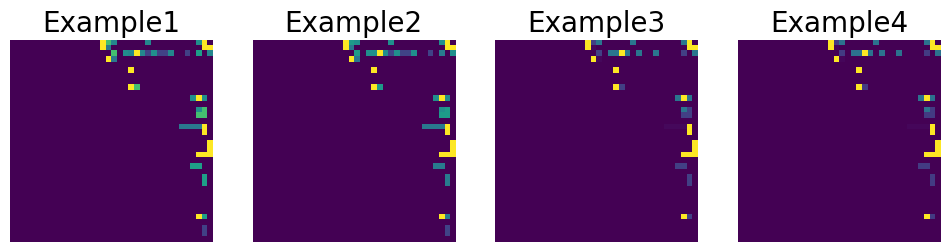

In [21]:
Font = 20

fig=plt.figure(figsize=(12,8), dpi= 100)
plt.subplot(141)
plt.imshow(X_REFINED_MDS[1,:].reshape(36,36), cmap = 'viridis') # 4x4 is the image dimension
plt.title("Example1", fontsize = Font)
plt.axis('off')

plt.subplot(142)
plt.imshow(X_REFINED_MDS[2,:].reshape(36,36), cmap = 'viridis')
plt.title("Example2", fontsize = Font)
plt.axis('off')

plt.subplot(143)
plt.imshow(X_REFINED_MDS[3,:].reshape(36,36), cmap = 'viridis')
plt.title("Example3", fontsize = Font)
plt.axis('off')


plt.subplot(144)
plt.imshow(X_REFINED_MDS[4,:].reshape(36,36), cmap = 'viridis')
plt.title("Example4", fontsize = Font)
plt.axis('off')

In [22]:
df = pd.read_csv("dataset.csv")
print(len(df), len(X_REFINED_MDS))

416 416


# Fitting a CNN Model

In [23]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import torch.nn.functional as F

In [24]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Reduced pooling size to preserve more information
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.dropout2 = nn.Dropout(0.25)
        # Additional convolutional layer to capture more complex patterns
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.dropout3 = nn.Dropout(0.25)
        # Batch normalization to stabilize learning
        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        # Adjusted for an additional pooling layer, resulting in 36/2/2/2 = 4.5 ~ 4 (floor) for the size of feature maps
        self.fc1 = nn.Linear(64 * 4 * 4, 256)  # Adjusted for added complexity and reduced pooling effect
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.dropout1(x)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout2(x)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # Additional pooling layer for the new conv layer
        x = self.dropout3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [25]:
import numpy as np
from sklearn.model_selection import train_test_split

df["Label"] = df["Label"].apply(lambda x: "Critical" if x == "Suspicious" else x)
y = df["Label"]

classes = np.unique(y)
X_train_list, X_test_list, y_train_list, y_test_list = [], [], [], []

for cls in classes:
    # Select indices for current class
    idx = np.where(y == cls)[0]
    
    # Split the dataset by class
    X_cls = X_REFINED_MDS[idx]
    y_cls = y[idx]
    
    # Split each class-specific subset into train and test
    X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)
    
    # Append the class-specific splits to the lists
    X_train_list.append(X_train_cls)
    X_test_list.append(X_test_cls)
    y_train_list.append(y_train_cls)
    y_test_list.append(y_test_cls)
    print(cls)
    print(len(y_train_cls), len(y_test_cls))

# Concatenate the class-specific train and test sets
X_train = np.concatenate(X_train_list)
X_test = np.concatenate(X_test_list)
y_train = np.concatenate(y_train_list)
y_test = np.concatenate(y_test_list)

Critical
180 45
Normal
152 39


In [26]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np

#y = df["Label"]
# Add stratify=y to ensure the same distribution of classes in both sets
#X_train, X_test, y_train, y_test = train_test_split(X_REFINED_MDS, y, test_size=0.2, random_state=42, stratify=y)

#y_train = y_train.values
#y_test = y_test.values

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({0: 180, 1: 152})
Counter({0: 45, 1: 39})


In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.stack([preprocess(img.reshape(36,36)) for img in X_train]).float()
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.stack([preprocess(img.reshape(36,36)) for img in X_test]).float()
y_test_tensor = torch.from_numpy(le.transform(y_test))

cuda


In [28]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [29]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-02,
    weight_decay=1e-05
)

In [30]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 2.713
[20] loss: 0.666
[40] loss: 0.629
[60] loss: 0.623
[80] loss: 0.609
[100] loss: 0.605
[120] loss: 0.614
[140] loss: 0.602
[160] loss: 0.597
[180] loss: 0.599
[199] loss: 0.599


In [31]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.705
The test accuracy was 0.726


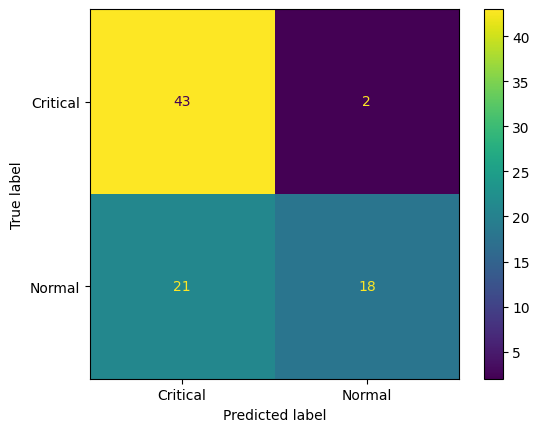

In [32]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)